# 17-bridge CPW–meander · Driven Terminal / Wave Ports

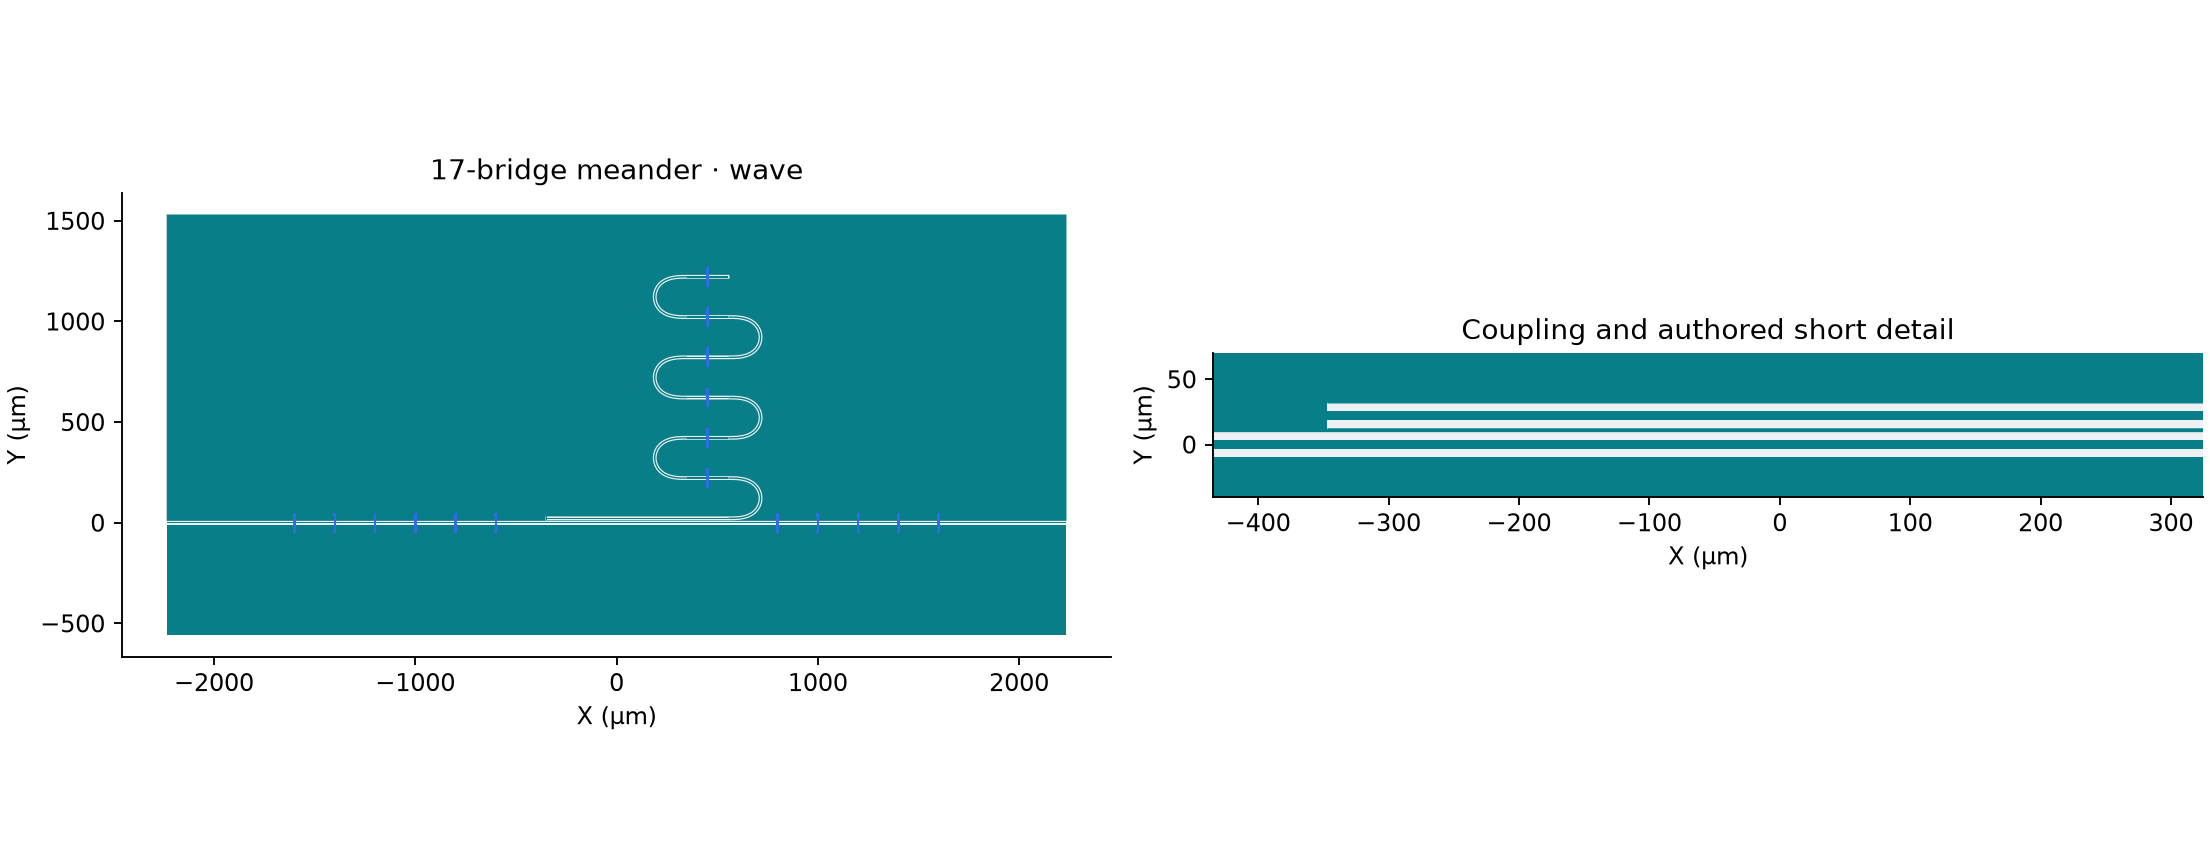

Use the same selected MTL/meander/17-bridge core **without launchers**.
P1/P2 are exterior YZ cuts at the left/right ends. Read the [Driven
Terminal
requirement](../../../../simulation/requirements/driven-terminal.qmd)
for the intended workflow; compare source port models with the [Lumped
variant](aedt_hfss_driven_terminal_lumped.ipynb), not numerical
equality.

Fresh construction uses the local shared-physical candidate, not a
published wheel. Retained results keep their original runtime
identities.

Published historical baseline:
[SCGSim](https://github.com/OrPenStrike/scgsim/tree/c9270c7e76e0b2df187dddde462079e00d410dd0).

## Action and identity

In [ ]:
import json
import subprocess
import sys
from importlib.metadata import version
from pathlib import Path
from uuid import uuid4

from IPython.display import display
from scgsim.aedt import (
    AedtResources,
    FrequencySweepSpec,
    HfssRunControl,
    TerminalPort,
    prepare_hfss_driven_from_geometry,
    prepare_planar_geometry_input,
    resolve_results,
)
from scgsim.geometry import (
    ApproximationProfile,
    GeometryBuildInput,
    LayoutPolygonSpec,
    LumpedSupport,
    SemanticEntitySpec,
    VacuumRegionSpec,
    apply_vacuum_region_to_stack,
)

import orcapen_sc_pdk
from orcapen_sc_pdk.cells import cpw_meander_airbridge_wave_coupon
from orcapen_sc_pdk.cells.simulation import get_cpw_meander_airbridge_source_records

WORKFLOW_ACTION = "run"  # author | prepare_handoff | prepare_only | run | analyze
VARIANT = "wave"
RUN_ID = f"meander-terminal-wave-{uuid4().hex[:12]}"
OUTPUT_ROOT = Path("notebooks/.artifacts/SCGSimExamples/ComponentSimulation/CpwMeanderAirbridge")
RUN_DIR = OUTPUT_ROOT / RUN_ID
RETURNED_RUN_DIR = OUTPUT_ROOT / "returned-run"
ANALYSIS_KIND = "strict"  # strict | receipt_only
display({name: version(name) for name in ("scgsim", "gdsfactory", "orcapen-sc-pdk")})

## Layout and cut-plane source facts

![Selected no-launcher source geometry; not a solved port
mode.](https://raw.githubusercontent.com/OrPenStrike/orcapen-sc-pdk/f4f509843c2c7177773798bf6a8a906f94c63a11/docs/_static/images/test-components/driven-terminal-wave-resonator.png)

In [ ]:
if WORKFLOW_ACTION != "analyze":
    orcapen_sc_pdk.activate()
    coupon = cpw_meander_airbridge_wave_coupon()
    coupon.plot()

The physical PDK stack is unchanged: M1 Al 100 nm, posts 3 µm, deck 0.3
µm. The no-launcher through ends reach the finite domain’s exterior. The
normal is outward −X / +X; Signal/reference membership is a separate
explicit source declaration. No internal launcher sheet is substituted
for either Wave port.

## Source records → caller-owned model

This one shared authoring cell wires the producer’s complete placed
rings to SCGSim’s public input records. It does not fit geometry, infer
connectivity or choose native object names. The source record’s `::`
keys and qualified occurrence/local Entity IDs are explicitly paired
below. Placed body rings are not transformed again; local neutral
supports carry their one recorded affine.

In [ ]:
if WORKFLOW_ACTION != "analyze":
    source = get_cpw_meander_airbridge_source_records(VARIANT)
    # Geometry classification is separate from physical superconductivity.
    # Preserve the full source record, including is_superconducting.
    geometry_material_kinds = {
        "superconductor": "conductor",
        "conductive": "conductor",
        "conductor": "conductor",
        "dielectric": "dielectric",
        "vacuum": "vacuum",
    }
    entity_ids = source["entity_aliases"]
    # This notebook explicitly adopts the producer's case grouping proposal.
    # It is not PDK-owned or a connectivity result from the native backend.
    final_nets = {
        entity_ids[source_id]: net
        for group, net in (("signal", "Signal"), ("ground", "Ground"))
        for source_id in source["case_net_groups"][group]
    }
    polygons, entities, conductor_layers, solution_regions = [], [], [], {}
    bounds = dict(
        zip(
            ("x_min_um", "y_min_um", "x_max_um", "y_max_um"),
            source["source_envelope"]["bounds_xy_um"],
            strict=True,
        )
    )
    for e in source["entities"]:
        sid = entity_ids[e["qualified_entity_id"]]
        physical_binding = source["physical_layer_bindings"][e["qualified_entity_id"]]
        level = source["source_levels"][physical_binding["source_level_id"]]
        material = source["material_records"][e["source_material"]]
        dielectric = material["material_kind"] == "dielectric"
        low, high = e["source_z_interval_um"]
        geometry = {"z_min_um": low, "z_max_um": high, "thickness_um": level["thickness"]}
        metadata = {
            "source_semantic_id": sid,
            "source_record_id": e["qualified_entity_id"],
            "source_occurrence_path": e["source_occurrence_path"],
            "source_local_entity_id": e["local_semantic_id"],
            "body_membership_id": e["body_membership_id"],
            "physical_layer": level["info"]["physical_layer"],
            "source_physical_layer_binding": physical_binding,
        }
        polygon_ids = []
        for p in e["placed_polygons"]:
            polygon_ids.append(p["polygon_id"])
            polygons.append(
                LayoutPolygonSpec(
                    polygon_id=p["polygon_id"],
                    layer="/".join(map(str, p["layer"])),
                    exterior=tuple(map(tuple, p["outer_um"])),
                    holes=tuple(tuple(map(tuple, h)) for h in p["holes_um"]),
                    object_name=sid,
                    net_name=final_nets.get(sid),
                    metadata={"coordinate_frame": p["coordinate_frame"]},
                )
            )
        if len(e["placed_polygons"]) == 1:
            p = e["placed_polygons"][0]
            geometry.update(outer_loop=p["outer_um"], hole_loops=p["holes_um"])
        if dielectric:
            geometry["domain_bounds_um"] = bounds
        record = dict(
            semantic_id=sid,
            role="solution_region" if dielectric else "metal",
            material_id=e["source_material"],
            material_kind=geometry_material_kinds[material["material_kind"]],
            priority=level["mesh_order"],
            geometry_kind="domain" if dielectric else "layout_extrusion",
            geometry=geometry,
            metadata=metadata,
        )
        part_role = None if dielectric else level["info"]["part_role"]
        entities.append(
            SemanticEntitySpec(
                **record,
                polygon_ids=tuple(polygon_ids),
                net_id=final_nets.get(sid),
                part_role=part_role,
                host_void_semantic_id=None if dielectric else "VACUUM_REGION",
            )
        )
        if dielectric:
            solution_regions[sid] = record
        else:
            conductor_layers.append({**record, "part_role": part_role})
    materials = {
        name: {
            **record,
            "kind": geometry_material_kinds[record["material_kind"]],
            "permittivity": record["relative_permittivity"],
        }
        for name, record in source["material_records"].items()
    }
    stack = {
        "materials": materials,
        "layers": conductor_layers,
        "solution_regions": solution_regions,
        "metadata": {},
    }
    source_bottom = min(e["source_z_interval_um"][0] for e in source["entities"])
    source_top = max(e["source_z_interval_um"][1] for e in source["entities"])
    envelope_bottom, envelope_top = source["source_envelope"]["z_interval_um"]
    stack = apply_vacuum_region_to_stack(
        stack,
        VacuumRegionSpec(
            0.0,
            0.0,
            0.0,
            0.0,
            source_bottom - envelope_bottom,
            envelope_top - source_top,
        ),
    )
    vacuum = stack["solution_regions"]["VACUUM_REGION"]
    entities.append(
        SemanticEntitySpec(
            semantic_id="VACUUM_REGION",
            role="solution_region",
            material_id=vacuum["material_id"],
            material_kind="vacuum",
            priority=0,
            geometry_kind="domain",
            geometry=vacuum["geometry"],
            metadata=vacuum["metadata"],
        )
    )
    supports = tuple(LumpedSupport.from_payload(s) for s in source["local_supports"])
    build_input = GeometryBuildInput(
        polygons=tuple(polygons),
        entities=tuple(entities),
        solution_regions=stack["solution_regions"],
        lumped_supports=supports,
        metadata={
            "source_dbu_um": source["source_dbu_um"],
            "caller_final_nets": final_nets,
            "source_coordinate_authority": "placed bodies / local supports",
        },
    )
    display(
        {
            "variant": VARIANT,
            "source_levels": source["source_levels"],
            "source_envelope": source["source_envelope"],
            "entity_count": len(source["entities"]),
            "supports": [s.to_payload() for s in supports],
        }
    )

## Wave membership and sweep controls

In [ ]:
MODEL = "thin_film"
APPROXIMATION_PROFILE = ApproximationProfile(name=MODEL, revision="v1", parameters={})
resources = AedtResources(cores=4, ram_limit_percent=20)
geometry_workers = 1
run_control = HfssRunControl(
    setup_name="Setup1",
    sweep_name="Sweep1",
    sweep=FrequencySweepSpec(3.0, 8.0, 3),
    maximum_passes=2,
    minimum_passes=1,
    minimum_converged_passes=1,
    maximum_delta_s=0.02,
    percent_refinement=30.0,
)
if WORKFLOW_ACTION != "analyze":
    ports = tuple(
        TerminalPort(
            index=i,
            name=f"P{i}",
            side={"left": "-X", "right": "+X"}[declaration["side"]],
            reference_objects=tuple(declaration["reference_entity_ids"]),
            signal_entity_ids=(declaration["signal_entity_id"],),
            deembed_um=0.0,
        )
        for i, declaration in enumerate(source["wave_sources"], 1)
    )
    display(source["wave_sources"])
    display([p.to_payload() for p in ports])
    display(run_control.to_payload())

The Wave cuts have zero X-region padding and share the explicitly
ordered positive Ground reference membership. The existing public Wave
treatment owns its port normalization; no unsupported normalization
option is invented here. The selected short sweep uses the original 3…8
GHz / 3-point control. Do not interpret it as a resolved resonator
lineshape or a convergence guarantee.

## Prepare / handoff

In [ ]:
HANDOFF = None
if WORKFLOW_ACTION in {"prepare_handoff", "prepare_only", "run"}:
    geometry = prepare_planar_geometry_input(
        build_input,
        prepared_stack=stack,
        modeling=APPROXIMATION_PROFILE.name,
    )
    HANDOFF = prepare_hfss_driven_from_geometry(
        modeling=APPROXIMATION_PROFILE.name,
        geometry=geometry,
        project_name=RUN_ID,
        design_name="MeanderTerminalWave",
        run_control=run_control,
        ports=ports,
        output_dir=RUN_DIR,
        geometry_workers=geometry_workers,
        resources=resources,
    )
    display(HANDOFF)

Preparation must retain actual finite Ground holes, all deck/post
bodies, source/effective Z and the declared enclosure. Its source input
is not proof of actual native Wave Port type, face membership or model
contact.

## Run: explicit native transaction

In [ ]:
if WORKFLOW_ACTION == "run":
    subprocess.run([str(HANDOFF.script_path)], cwd=HANDOFF.run_dir, check=True)

## Prepare-only native model inspection

Select `prepare_only` to build, read back, save and release the native
model without Analyze. This does not produce solved physics results.

In [ ]:
if WORKFLOW_ACTION == "prepare_only":
    from scgsim.aedt import resolve_prepared_model

    subprocess.run(
        [
            sys.executable,
            "-m",
            "scgsim.aedt.run",
            "--handoff",
            str(HANDOFF.metadata_path),
            "--execute",
            "--prepare-only",
        ],
        check=True,
    )
    display(resolve_prepared_model(HANDOFF.run_dir))

## Returned Run: fresh kernel / relocated input

In [ ]:
RESULT = None
if WORKFLOW_ACTION in {"run", "analyze"}:
    if WORKFLOW_ACTION == "run" or ANALYSIS_KIND == "strict":
        RESULT = resolve_results(HANDOFF.run_dir if WORKFLOW_ACTION == "run" else RETURNED_RUN_DIR)
    elif ANALYSIS_KIND == "receipt_only":
        display(json.loads((RETURNED_RUN_DIR / "metadata/aedt_run_receipt.json").read_text()))
    else:
        raise ValueError("choose strict or receipt_only analysis")

### Terminal S-data and native provenance

In [ ]:
if RESULT is not None:
    display(RESULT.physics_results())
    display(RESULT.simulation_benchmark())
    display(RESULT.show_all_results(show_details=True))

Inspect actual Wave boundary labels, terminal order/reference
conductors, frequency/units, deembedding zero, S-data and retained
warnings. Keep native readback, strict completion and Report
presentation distinct. No extra field solve, second Analyze, retry or
reference-plane matching is introduced.